# Tell or Trap

**A scouting tool for RB/TE assignments on pass plays.** For a chosen team (or one player) and a historical cutoff week, it

1. finds situations *visible by the snap* in which a back or tight end blocks, releases into a route, or chips-then-releases more often than he usually does,
2. checks each of those tendencies in the games *after* the cutoff, and
3. pulls up the supporting plays and the exceptions, with a freeze-frame at the snap and a reveal.

A tendency that keeps showing up later is a **Tell**. One that does not is a **Trap**.

**Read this before trusting a number**
- The dataset contains dropbacks only, so everything here is conditional on a pass play. It says nothing about run versus pass.
- Results are associations, not causes. Opponent, game plan and injuries are not controlled for.
- Many situations are searched, so some discovered tendencies will be noise. The later-game check is the guard against that.
- We had already looked at some Weeks 6-8 findings before writing this notebook. The later-game check is therefore **retrospective**, not an untouched test.
- Not every team or player yields a usable tendency. The notebook says so when that happens.

## 1. Configuration
Every choice lives in this cell. Nothing below hardcodes a team, a player or a percentage.

In [6]:
CONFIG = {
    # --- data ---
    "DATA_DIR": "data",                  # relative to this notebook
    "OUTPUT_DIR": "outputs",
    # Only used if a file is missing locally; downloads are cached in DATA_DIR.
    "DATA_URL": "https://raw.githubusercontent.com/ThompsonJamesBliss/nfl-big-data-bowl-regional-event-data/main/data",
    # --- who and when ---
    "TEAM": "SEA",                  # offense being scouted (team abbreviation)
    "PLAYER": None,                      # displayName or nflId; None = every RB/TE on TEAM
    "CUTOFF_WEEK": 5,                    # discovery uses weeks <= cutoff, checking uses weeks > cutoff
    "POSITIONS": ["RB", "TE"],           # add "FB" to include fullbacks
    # --- what counts as a tendency ---
    # "route" can be added, but most backs/TEs already release on most pass snaps, so route tells are rarely news
    "OUTCOMES": ["block", "chip_release"],
    "FEATURES": ["down", "distance", "formation", "personnel", "alignment",
                 "align_group", "backs", "box", "field", "score", "two_minute"],
    "MAX_CONDITIONS": 2,                 # a situation is 1 or 2 feature=value conditions
    "MIN_PLAYER_PLAYS": 30,              # player needs this many pass snaps before the cutoff
    "MIN_DISC_PLAYS": 10,                # situation needs this many plays before the cutoff
    "MIN_DISC_GAMES": 3,                 # ... spread over at least this many games
    "MIN_LIFT": 0.15,                    # situation rate minus the player's usual rate
    "WILSON_Z": 1.64,                    # used only to rank tendencies conservatively
    # --- later-game check ---
    "MIN_EVAL_PLAYS": 5,                 # fewer later plays than this = "too few later plays"
    "HOLD_LIFT": 0.10,                   # later rate must beat later usual rate by this to be a Tell
    # --- display ---
    "TOP_K": 10,                         # tendencies kept per team, ranked on pre-cutoff data only
    "DEMO_RULE_RANK": 0,                 # which ranked tendency to demo (0 = top)
}

## 2. Reusable functions
### 2a. Loading (local cache first, download only if a file is missing)

In [7]:
import itertools
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

KEYS = ["gameId", "playId", "nflId"]


def ensure_file(rel_path, cfg):
    """Return a local path for a dataset file, downloading it once if it is not cached."""
    path = Path(cfg["DATA_DIR"]) / rel_path
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        url = cfg["DATA_URL"].rstrip("/") + "/" + rel_path
        print("downloading", url)
        urllib.request.urlretrieve(url, str(path))
    return path


def load_tables(cfg):
    """Load the four small tables. Tracking is NOT loaded here."""
    return {name: pd.read_csv(ensure_file(name + ".csv", cfg))
            for name in ["games", "plays", "players", "pffScoutingData"]}


_TRACKING_CACHE = {}


def load_tracking(game_id, cfg):
    """Load one game's tracking file (cached in memory), with coordinates flipped so the offense always moves right."""
    game_id = int(game_id)
    if game_id not in _TRACKING_CACHE:
        t = pd.read_csv(ensure_file("tracking/tracking_{}.csv".format(game_id), cfg))
        left = t["playDirection"] == "left"
        t["x_std"] = np.where(left, 120.0 - t["x"], t["x"])
        t["y_std"] = np.where(left, 160.0 / 3.0 - t["y"], t["y"])
        _TRACKING_CACHE[game_id] = t
    return _TRACKING_CACHE[game_id]

### 2b. Outcome labels and snap-time features
**Outcome (what we try to anticipate)** comes from PFF's post-snap charting:

| label | PFF fields |
|---|---|
| `route` | role = Pass Route, no block type |
| `chip_release` | role = Pass Route, block type CH (chip) or SR (set and release) |
| `block` | role = Pass Block with a real block type |
| `ambiguous` | anything else (kept and counted, never dropped) |

**Predictor inputs** use only what is known by the snap: down, distance, field position, score, clock, formation, personnel, box count and where the player lined up.
Play descriptions, play results, pressure outcomes, coverage, play-action and dropback type are never used as inputs; the guard below fails loudly if one sneaks in.

In [8]:
FORBIDDEN_INPUTS = {
    "playDescription", "passResult", "penaltyYards", "prePenaltyPlayResult", "playResult",
    "foulName1", "foulName2", "foulName3", "dropBackType", "pff_playAction", "pff_passCoverage",
    "pff_passCoverageType", "pff_role", "pff_blockType", "pff_hit", "pff_hurry", "pff_sack",
    "pff_beatenByDefender", "pff_hitAllowed", "pff_hurryAllowed", "pff_sackAllowed",
    "pff_nflIdBlockedPlayer", "pff_backFieldBlock",
}

# feature name -> raw columns it is built from (all known by the snap)
FEATURE_SOURCES = {
    "down": ["down"],
    "distance": ["yardsToGo"],
    "formation": ["offenseFormation"],
    "personnel": ["personnelO"],
    "alignment": ["pff_positionLinedUp"],
    "align_group": ["pff_positionLinedUp"],
    "backs": ["pff_positionLinedUp"],
    "box": ["defendersInBox"],
    "field": ["yardlineSide", "yardlineNumber", "possessionTeam"],
    "score": ["preSnapHomeScore", "preSnapVisitorScore", "possessionTeam", "homeTeamAbbr"],
    "two_minute": ["quarter", "gameClock"],
}


def check_no_leakage(cfg):
    """Raise if any configured feature is unknown or built from a post-snap column."""
    for f in cfg["FEATURES"]:
        if f not in FEATURE_SOURCES:
            raise ValueError("Unknown feature: " + f)
        bad = FORBIDDEN_INPUTS.intersection(FEATURE_SOURCES[f])
        if bad:
            raise ValueError("Feature {} uses post-snap columns {}".format(f, sorted(bad)))
    return True


def _align_group(a):
    if a.startswith(("HB", "FB")):
        return "backfield"
    if a.startswith("TE"):
        return "inline"
    if a in ("LWR", "RWR"):
        return "wide"
    if a.startswith("S") and a.endswith("WR"):
        return "slot"
    return "other"


def build_player_plays(tables, cfg):
    """One row per (gameId, playId, nflId) for offensive RB/TE snaps, with outcome label and snap-time features."""
    games, plays, players, pff = (tables[k] for k in ["games", "plays", "players", "pffScoutingData"])

    # number of backs lined up in the backfield on each play (from alignment only)
    lined = pff["pff_positionLinedUp"].fillna("")
    n_backs = (pff[lined.str.startswith(("HB", "FB"))]
               .groupby(["gameId", "playId"]).size().rename("n_backs").reset_index())

    m = pff.merge(players[["nflId", "displayName", "officialPosition"]], on="nflId", how="left")
    m = m[m["officialPosition"].isin(cfg["POSITIONS"]) & m["pff_role"].isin(["Pass Route", "Pass Block"])]
    m = m.merge(plays, on=["gameId", "playId"], how="left")
    m = m.merge(games[["gameId", "week", "homeTeamAbbr", "visitorTeamAbbr"]], on="gameId", how="left")
    m = m.merge(n_backs, on=["gameId", "playId"], how="left")
    m = m.reset_index(drop=True)
    m["team"] = m["possessionTeam"]          # offensive role => player is on the possession team
    m["opponent"] = m["defensiveTeam"]

    # ---- outcome label (post-snap; never used as an input) ----
    role = m["pff_role"]
    bt = m["pff_blockType"].fillna("none")
    m["assignment"] = np.select(
        [(role == "Pass Route") & (bt == "none"),
         (role == "Pass Route") & bt.isin(["CH", "SR"]),
         (role == "Pass Block") & ~bt.isin(["none", "NB"])],
        ["route", "chip_release", "block"], default="ambiguous")
    m["assignment_detail"] = role + " / blockType=" + bt
    for o in ["route", "chip_release", "block", "ambiguous"]:
        m["is_" + o] = (m["assignment"] == o).astype(int)

    # ---- snap-time features ----
    m["down"] = m["down"].map({1: "1st", 2: "2nd", 3: "3rd", 4: "4th"}).fillna("2pt/other")
    m["distance"] = np.select([m["yardsToGo"] <= 3, m["yardsToGo"] <= 6],
                              ["short 1-3", "medium 4-6"], default="long 7+")
    m["formation"] = m["offenseFormation"].fillna("UNKNOWN")
    m["personnel"] = m["personnelO"].fillna("UNKNOWN")
    m["alignment"] = m["pff_positionLinedUp"].fillna("UNKNOWN")
    m["align_group"] = m["alignment"].map(_align_group)
    nb = m["n_backs"].fillna(0)
    m["backs"] = np.select([nb == 0, nb == 1], ["0 backs", "1 back"], default="2+ backs")
    box = m["defendersInBox"]
    m["box"] = np.select([box.isna(), box <= 5, box == 6], ["unknown", "light 5-", "6"], default="heavy 7+")
    own_side = (m["yardlineSide"] == m["possessionTeam"]).fillna(False).astype(bool)
    ytg = np.where(m["yardlineSide"].isna(), 50, np.where(own_side, 100 - m["yardlineNumber"], m["yardlineNumber"]))
    m["yards_to_goal"] = ytg
    m["field"] = np.select([ytg <= 20, ytg <= 50, ytg >= 80],
                           ["red zone", "opp 21-50", "backed up own 20-"], default="own 21-49")
    is_home = (m["possessionTeam"] == m["homeTeamAbbr"]).fillna(False).astype(bool)
    diff = np.where(is_home, m["preSnapHomeScore"] - m["preSnapVisitorScore"],
                    m["preSnapVisitorScore"] - m["preSnapHomeScore"])
    m["score"] = np.select([diff > 0, diff < 0], ["leading", "trailing"], default="tied")
    clock = m["gameClock"].str.split(":", expand=True).astype(int)
    secs = clock[0] * 60 + clock[1]
    m["two_minute"] = np.where(m["quarter"].isin([2, 4]) & (secs <= 120), "yes", "no")

    keep = (KEYS + ["week", "team", "opponent", "displayName", "officialPosition", "quarter", "gameClock",
                    "yardsToGo", "yards_to_goal"] + list(FEATURE_SOURCES) +
            ["assignment", "assignment_detail", "is_route", "is_chip_release", "is_block", "is_ambiguous"])
    out = m[keep].sort_values(["week", "gameId", "playId", "nflId"]).reset_index(drop=True)
    assert not out.duplicated(KEYS).any(), "duplicate gameId/playId/nflId rows"
    return out

### 2c. Discovery (before the cutoff) and checking (after the cutoff)
Splits are chronological by week, never random.
A tendency is *player + situation + outcome*, where the outcome rate in that situation beats the player's own usual rate by `MIN_LIFT`.
Ranking uses only pre-cutoff data (Wilson lower bound minus the usual rate), so later games cannot influence which tendencies are shown.

In [10]:
def resolve_player(pp, team, player):
    """Turn CONFIG['PLAYER'] (None, nflId or displayName) into an nflId or None."""
    if player is None:
        return None
    if isinstance(player, (int, np.integer)):
        return int(player)
    hit = pp[(pp["team"] == team) & (pp["displayName"].str.lower() == str(player).lower())]["nflId"].unique()
    if len(hit) != 1:
        raise ValueError("PLAYER {!r} matched {} RB/TE on {}".format(player, len(hit), team))
    return int(hit[0])


def match_mask(df, conditions):
    """Boolean mask of rows that satisfy every feature=value condition."""
    mask = np.ones(len(df), dtype=bool)
    for f, v in conditions.items():
        mask &= (df[f] == v).to_numpy()
    return mask


def wilson_lower(k, n, z):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    p = k / n
    return (p + z * z / (2 * n) - z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / (1 + z * z / n)


def discover(pp, cfg, team=None, nfl_id=None):
    """Find tendencies using only weeks <= CUTOFF_WEEK. team=None searches every team."""
    d = pp[pp["week"] <= cfg["CUTOFF_WEEK"]]
    if team is not None:
        d = d[d["team"] == team]
    if nfl_id is not None:
        d = d[d["nflId"] == nfl_id]
    outcomes = list(cfg["OUTCOMES"])
    subj = ["team", "nflId", "displayName", "officialPosition"]
    k_aggs = {"k_" + o: ("is_" + o, "sum") for o in outcomes}
    base = d.groupby(subj).agg(base_n=("playId", "size"), base_games=("gameId", "nunique"),
                               **{"base_" + k: v for k, v in k_aggs.items()}).reset_index()
    base = base[base["base_n"] >= cfg["MIN_PLAYER_PLAYS"]]
    cols = (subj + ["outcome", "situation", "conditions", "n_conditions", "disc_k", "disc_n", "disc_games",
                    "disc_ambiguous", "disc_rate", "base_k", "base_n", "base_games", "base_rate", "lift", "score"])
    if d.empty or base.empty:
        return pd.DataFrame(columns=cols)

    cands = []
    for r in range(1, cfg["MAX_CONDITIONS"] + 1):
        for combo in itertools.combinations(cfg["FEATURES"], r):
            combo = list(combo)
            g = d.groupby(subj + combo).agg(disc_n=("playId", "size"), disc_games=("gameId", "nunique"),
                                            disc_ambiguous=("is_ambiguous", "sum"), **k_aggs).reset_index()
            g = g[(g["disc_n"] >= cfg["MIN_DISC_PLAYS"]) & (g["disc_games"] >= cfg["MIN_DISC_GAMES"])]
            if g.empty:
                continue
            vals = list(g[combo].itertuples(index=False, name=None))
            g = g.drop(columns=combo)
            g["conditions"] = [dict(zip(combo, v)) for v in vals]
            g["situation"] = [" & ".join("{}={}".format(f, x) for f, x in zip(combo, v)) for v in vals]
            g["n_conditions"] = r
            cands.append(g)
    if not cands:
        return pd.DataFrame(columns=cols)
    cand = pd.concat(cands, ignore_index=True).merge(base, on=subj, how="inner")

    rules = []
    for o in outcomes:
        c = cand.copy()
        c["outcome"] = o
        c["disc_k"] = c["k_" + o]
        c["base_k"] = c["base_k_" + o]
        rules.append(c)
    rules = pd.concat(rules, ignore_index=True)
    rules["disc_rate"] = rules["disc_k"] / rules["disc_n"]
    rules["base_rate"] = rules["base_k"] / rules["base_n"]
    rules["lift"] = rules["disc_rate"] - rules["base_rate"]
    rules["score"] = wilson_lower(rules["disc_k"], rules["disc_n"], cfg["WILSON_Z"]) - rules["base_rate"]
    rules = rules[rules["lift"] >= cfg["MIN_LIFT"]].copy()
    if rules.empty:
        return pd.DataFrame(columns=cols)

    # drop situations that describe exactly the same set of plays (keep the simplest wording)
    by_player = {key: grp for key, grp in d.groupby(["team", "nflId"])}
    sigs = []
    for row in rules.itertuples(index=False):
        grp = by_player[(row.team, row.nflId)]
        sigs.append(hash(tuple(grp.index[match_mask(grp, row.conditions)])))
    rules["_sig"] = sigs
    rules = (rules.sort_values(["n_conditions", "situation"])
             .drop_duplicates(["team", "nflId", "outcome", "_sig"])
             .sort_values(["score", "disc_n", "situation", "outcome", "nflId"],
                          ascending=[False, False, True, True, True])
             .reset_index(drop=True))
    return rules[cols]


def top_rules(rules, cfg):
    """Keep the TOP_K highest-ranked tendencies per team (ranking uses pre-cutoff data only)."""
    if rules.empty:
        return rules.copy()
    r = rules.sort_values(["team", "score", "disc_n", "situation", "outcome", "nflId"],
                          ascending=[True, False, False, True, True, True]).copy()
    r["rank"] = r.groupby("team").cumcount()
    return r[r["rank"] < cfg["TOP_K"]].reset_index(drop=True)


def evaluate(pp, rules, cfg):
    """Check each tendency in weeks > CUTOFF_WEEK and label it Tell / Trap / too few later plays."""
    later = pp[pp["week"] > cfg["CUTOFF_WEEK"]]
    by_player = {key: grp for key, grp in later.groupby(["team", "nflId"])}
    rows = []
    for row in rules.itertuples(index=False):
        grp = by_player.get((row.team, row.nflId))
        col = "is_" + row.outcome
        if grp is None:
            rows.append((0, 0, 0, 0, 0, 0, 0))
            continue
        sit = grp[match_mask(grp, row.conditions)]
        rows.append((int(sit[col].sum()), len(sit), sit["gameId"].nunique(), int(sit["is_ambiguous"].sum()),
                     int(grp[col].sum()), len(grp), grp["gameId"].nunique()))
    out = rules.copy()
    ev = pd.DataFrame(rows, index=out.index, columns=["later_k", "later_n", "later_games", "later_ambiguous",
                                                     "later_base_k", "later_base_n", "later_base_games"])
    out = pd.concat([out, ev], axis=1)
    out["later_rate"] = out["later_k"] / out["later_n"].replace(0, np.nan)
    out["later_base_rate"] = out["later_base_k"] / out["later_base_n"].replace(0, np.nan)
    out["later_lift"] = out["later_rate"] - out["later_base_rate"]
    out["verdict"] = np.select(
        [out["later_n"] < cfg["MIN_EVAL_PLAYS"], out["later_lift"] >= cfg["HOLD_LIFT"]],
        ["Too few later plays", "Tell (held)"], default="Trap (did not hold)")
    return out


def _frac(k, n, games):
    if n == 0:
        return "0 plays"
    return "{}/{} ({:.0%}) in {} games".format(int(k), int(n), k / n, int(games))


def present(ev):
    """Readable version of an evaluated rules table: every percentage is shown with its count and games."""
    if ev.empty:
        return pd.DataFrame()
    return pd.DataFrame({
        "team": ev["team"], "nflId": ev["nflId"], "player": ev["displayName"], "pos": ev["officialPosition"],
        "situation": ev["situation"], "outcome": ev["outcome"],
        "before cutoff: in situation": [_frac(k, n, g) for k, n, g in zip(ev["disc_k"], ev["disc_n"], ev["disc_games"])],
        "before cutoff: usual": [_frac(k, n, g) for k, n, g in zip(ev["base_k"], ev["base_n"], ev["base_games"])],
        "later: in situation": [_frac(k, n, g) for k, n, g in zip(ev["later_k"], ev["later_n"], ev["later_games"])],
        "later: usual": [_frac(k, n, g) for k, n, g in zip(ev["later_base_k"], ev["later_base_n"], ev["later_base_games"])],
        "ambiguous (before/later)": ["{}/{}".format(int(a), int(b)) for a, b in zip(ev["disc_ambiguous"], ev["later_ambiguous"])],
        "verdict": ev["verdict"],
    }, index=ev.index)

### 2d. Evidence retrieval
Returns the actual plays behind a tendency, keeping `gameId`, `playId` and `nflId`, and marking each one as support, exception or ambiguous.

In [11]:
EVIDENCE_COLS = ["gameId", "playId", "nflId", "week", "opponent", "quarter", "gameClock", "down", "yardsToGo",
                 "formation", "personnel", "alignment", "box", "assignment", "assignment_detail"]


def rule_plays(pp, rule, cfg, phase):
    """Plays of the rule's player in the rule's situation. phase is 'before' or 'later'."""
    d = pp[(pp["team"] == rule["team"]) & (pp["nflId"] == rule["nflId"])]
    d = d[d["week"] <= cfg["CUTOFF_WEEK"]] if phase == "before" else d[d["week"] > cfg["CUTOFF_WEEK"]]
    d = d[match_mask(d, rule["conditions"])][EVIDENCE_COLS].copy()
    d["evidence"] = np.select([d["assignment"] == rule["outcome"], d["assignment"] == "ambiguous"],
                              ["support", "ambiguous"], default="exception")
    return d.sort_values(["week", "gameId", "playId"]).reset_index(drop=True)

### 2e. Tracking helpers and figures
Tracking is read only for the games of the plays being shown. The freeze-frame uses the `ball_snap` frame; the reveal adds the player's path from the snap to the pass, sack or run event.

In [12]:
END_EVENTS = ["pass_forward", "autoevent_passforward", "qb_sack", "qb_strip_sack", "run"]
COLORS = {"offense": "#2a6fbb", "defense": "#9aa0a6", "focus": "#e8590c", "ball": "#7a4a1e"}


def play_tracking(game_id, play_id, cfg):
    t = load_tracking(game_id, cfg)
    return t[t["playId"] == int(play_id)]


def snap_frame_id(tp):
    """Frame of the snap, or None if the play has no snap event (kept explicit, never guessed)."""
    for ev in ["ball_snap", "autoevent_ballsnap"]:
        f = tp.loc[tp["event"] == ev, "frameId"]
        if len(f):
            return int(f.min())
    return None


def window_end_frame(tp, snap):
    f = tp.loc[tp["event"].isin(END_EVENTS) & (tp["frameId"] > snap), "frameId"]
    return int(f.min()) if len(f) else int(tp["frameId"].max())


def fig_play(pp, tables, cfg, game_id, play_id, nfl_id, title, reveal=False):
    """Freeze-frame at the snap. With reveal=True, add the focus player's post-snap path."""
    tp = play_tracking(game_id, play_id, cfg)
    snap = snap_frame_id(tp)
    if snap is None:
        print("No snap event in tracking for gameId={} playId={}; cannot draw.".format(game_id, play_id))
        return None
    plays, players, pff = tables["plays"], tables["players"], tables["pffScoutingData"]
    play = plays[(plays["gameId"] == game_id) & (plays["playId"] == play_id)].iloc[0]
    fr = tp[tp["frameId"] == snap].merge(players[["nflId", "displayName", "officialPosition"]], on="nflId", how="left")
    lined = pff[(pff["gameId"] == game_id) & (pff["playId"] == play_id)][["nflId", "pff_positionLinedUp"]]
    fr = fr.merge(lined, on="nflId", how="left")     # alignment only; no post-snap role in the hover
    ball = fr[fr["team"] == "football"]
    ppl = fr[fr["team"] != "football"]
    off = ppl[(ppl["team"] == play["possessionTeam"]) & (ppl["nflId"] != nfl_id)]
    dfn = ppl[ppl["team"] != play["possessionTeam"]]
    foc = ppl[ppl["nflId"] == nfl_id]
    los = float(ball["x_std"].iloc[0]) if len(ball) else float(off["x_std"].max())
    mid = float(ball["y_std"].iloc[0]) if len(ball) else float(off["y_std"].mean())
    y_lo, y_hi = max(0.0, mid - 22), min(160.0 / 3.0, mid + 22)

    def hover(d):
        return [("{} ({}), lined up {}".format(n, p, a)) for n, p, a in
                zip(d["displayName"], d["officialPosition"], d["pff_positionLinedUp"])]

    def jersey(d):
        return [str(int(j)) if pd.notna(j) else "" for j in d["jerseyNumber"]]

    fig = go.Figure()
    fig.add_shape(type="line", x0=los, x1=los, y0=y_lo, y1=y_hi, line=dict(color="#444444", width=1, dash="dot"))
    for d, name, color, size in [(dfn, "Defense " + str(play["defensiveTeam"]), COLORS["defense"], 15),
                                 (off, "Offense " + str(play["possessionTeam"]), COLORS["offense"], 15),
                                 (foc, "Player in question", COLORS["focus"], 21)]:
        fig.add_trace(go.Scatter(x=d["x_std"], y=d["y_std"], mode="markers+text", name=name,
                                 text=jersey(d), textfont=dict(color="white", size=8),
                                 hovertext=hover(d), hoverinfo="text",
                                 marker=dict(size=size, color=color, line=dict(color="white", width=1))))
    if len(ball):
        fig.add_trace(go.Scatter(x=ball["x_std"], y=ball["y_std"], mode="markers", name="Ball", hoverinfo="name",
                                 marker=dict(size=9, color=COLORS["ball"], symbol="diamond")))
    if reveal and len(foc):
        end = window_end_frame(tp, snap)
        path = tp[(tp["nflId"] == nfl_id) & (tp["frameId"] >= snap) & (tp["frameId"] <= end)].sort_values("frameId")
        fig.add_trace(go.Scatter(x=path["x_std"], y=path["y_std"], mode="lines", name="Path after the snap",
                                 line=dict(color=COLORS["focus"], width=4), hoverinfo="skip"))
        fig.add_trace(go.Scatter(x=path["x_std"].iloc[-1:], y=path["y_std"].iloc[-1:], mode="markers",
                                 name="Position at pass/sack/run", hoverinfo="name",
                                 marker=dict(size=14, color=COLORS["focus"], symbol="x")))
    fig.update_layout(title=title, template="plotly_white", height=680, width=980, margin=dict(t=110),
                      legend=dict(orientation="h", y=-0.15),
                      xaxis=dict(range=[los - 18, los + 37], title="yards (offense moves right; dotted line = ball at snap)",
                                 showgrid=True, dtick=5, zeroline=False, constrain="domain"),
                      yaxis=dict(range=[y_lo, y_hi], title="", showticklabels=False, showgrid=False,
                                 scaleanchor="x", scaleratio=1, zeroline=False, constrain="domain"))
    return fig


def fig_tendency(rule, cfg):
    """Bar chart of one evaluated tendency: situation rate vs usual rate, before and after the cutoff."""
    c = cfg["CUTOFF_WEEK"]
    labels = ["Weeks 1-{}<br>in this situation".format(c), "Weeks 1-{}<br>all his pass snaps".format(c),
              "After week {}<br>in this situation".format(c), "After week {}<br>all his pass snaps".format(c)]
    ks = [rule["disc_k"], rule["base_k"], rule["later_k"], rule["later_base_k"]]
    ns = [rule["disc_n"], rule["base_n"], rule["later_n"], rule["later_base_n"]]
    gs = [rule["disc_games"], rule["base_games"], rule["later_games"], rule["later_base_games"]]
    rates = [(k / n if n else 0.0) for k, n in zip(ks, ns)]
    text = ["{:.0%}<br>{}/{} plays<br>{} games".format(r, int(k), int(n), int(g)) if n else "no plays"
            for r, k, n, g in zip(rates, ks, ns, gs)]
    fig = go.Figure(go.Bar(x=labels, y=rates, text=text, textposition="outside",
                           marker_color=[COLORS["focus"], COLORS["defense"], COLORS["focus"], COLORS["defense"]]))
    fig.update_layout(
        title="{} ({}, {}): how often '{}' when {}<br><sup>Verdict: {} | association, not cause | later check is retrospective</sup>".format(
            rule["displayName"], rule["officialPosition"], rule["team"], rule["outcome"], rule["situation"], rule["verdict"]),
        template="plotly_white", height=520, width=980, showlegend=False,
        yaxis=dict(range=[0, 1.25], tickformat=".0%", title="share of his pass snaps"))
    return fig


def save_fig(fig, name, cfg):
    out = Path(cfg["OUTPUT_DIR"])
    out.mkdir(parents=True, exist_ok=True)
    path = out / name
    fig.write_html(str(path), include_plotlyjs="cdn")
    return path

## 3. Load the tables and label every RB/TE pass snap
Tracking is not loaded yet. The table below shows how many snaps fall into each outcome label, including the ambiguous ones.

In [13]:
check_no_leakage(CONFIG)
tables = load_tables(CONFIG)
pp = build_player_plays(tables, CONFIG)

print("Player-snaps: {:,} | plays: {:,} | games: {} | players: {} | weeks {}-{}".format(
    len(pp), pp[["gameId", "playId"]].drop_duplicates().shape[0], pp["gameId"].nunique(),
    pp["nflId"].nunique(), pp["week"].min(), pp["week"].max()))
display(pd.crosstab(pp["assignment"], pp["officialPosition"], margins=True))
print("What the 'ambiguous' label contains:")
display(pp[pp["assignment"] == "ambiguous"].groupby(["assignment_detail", "officialPosition"]).size()
        .unstack(fill_value=0))

Player-snaps: 19,044 | plays: 8,543 | games: 122 | players: 246 | weeks 1-8


officialPosition,RB,TE,All
assignment,,,
ambiguous,341,164,505
block,1253,1340,2593
chip_release,559,1101,1660
route,6395,7891,14286
All,8548,10496,19044


What the 'ambiguous' label contains:


officialPosition,RB,TE
assignment_detail,,
Pass Block / blockType=NB,177,64
Pass Block / blockType=none,124,28
Pass Route / blockType=BH,19,1
Pass Route / blockType=CL,0,3
Pass Route / blockType=NB,11,6
Pass Route / blockType=PA,0,38
Pass Route / blockType=PP,1,7
Pass Route / blockType=PR,0,1
Pass Route / blockType=PT,0,7


## 4. Discover tendencies before the cutoff
Only weeks up to `CUTOFF_WEEK` are used here. The ranking cannot see later games.

In [14]:
TEAM = CONFIG["TEAM"]
PLAYER_ID = resolve_player(pp, TEAM, CONFIG["PLAYER"])
team_rules = top_rules(discover(pp, CONFIG, team=TEAM, nfl_id=PLAYER_ID), CONFIG)

d_team = pp[(pp["team"] == TEAM) & (pp["week"] <= CONFIG["CUTOFF_WEEK"])]
print("{}: {:,} RB/TE pass snaps in {} games through week {}.".format(
    TEAM, len(d_team), d_team["gameId"].nunique(), CONFIG["CUTOFF_WEEK"]))
if team_rules.empty:
    print("No tendency met the thresholds for this selection. That is a valid result; try another team or relax CONFIG.")
else:
    print("{} tendencies kept (top {} by pre-cutoff ranking).".format(len(team_rules), CONFIG["TOP_K"]))

SEA: 350 RB/TE pass snaps in 5 games through week 5.
10 tendencies kept (top 10 by pre-cutoff ranking).


## 5. Check them in later games (retrospective)
Complete results for every tendency kept above, including the ones that failed. Each percentage is shown with its play count and number of games.

In [15]:
team_eval = evaluate(pp, team_rules, CONFIG)
if not team_eval.empty:
    display(present(team_eval))
    print("Verdicts for {}:".format(TEAM))
    display(team_eval["verdict"].value_counts().rename("tendencies").to_frame())

,team,nflId,player,pos,situation,outcome,before cutoff: in situation,before cutoff: usual,later: in situation,later: usual,ambiguous (before/later),verdict
0,SEA,46189,Will Dissly,TE,formation=SINGLEBACK & score=tied,block,7/10 (70%) in 4 games,17/91 (19%) in 5 games,4/5 (80%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
1,SEA,46189,Will Dissly,TE,distance=long 7+ & formation=SINGLEBACK,block,12/21 (57%) in 5 games,17/91 (19%) in 5 games,8/10 (80%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
2,SEA,46189,Will Dissly,TE,down=1st & formation=SINGLEBACK,block,11/19 (58%) in 5 games,17/91 (19%) in 5 games,6/6 (100%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
3,SEA,46189,Will Dissly,TE,formation=SINGLEBACK & alignment=TE-R,block,11/19 (58%) in 5 games,17/91 (19%) in 5 games,5/8 (62%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
4,SEA,46189,Will Dissly,TE,down=1st & score=tied,block,8/13 (62%) in 4 games,17/91 (19%) in 5 games,1/3 (33%) in 2 games,15/43 (35%) in 3 games,0/0,Too few later plays
5,SEA,46189,Will Dissly,TE,down=1st & align_group=inline,block,12/23 (52%) in 5 games,17/91 (19%) in 5 games,9/11 (82%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
6,SEA,46189,Will Dissly,TE,alignment=TE-R & score=tied,block,7/12 (58%) in 4 games,17/91 (19%) in 5 games,2/3 (67%) in 2 games,15/43 (35%) in 3 games,0/0,Too few later plays
7,SEA,46189,Will Dissly,TE,down=1st & alignment=TE-R,block,10/19 (53%) in 5 games,17/91 (19%) in 5 games,5/6 (83%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
8,SEA,46189,Will Dissly,TE,align_group=inline & score=tied,block,8/15 (53%) in 4 games,17/91 (19%) in 5 games,4/5 (80%) in 3 games,15/43 (35%) in 3 games,0/0,Tell (held)
9,SEA,46189,Will Dissly,TE,formation=SINGLEBACK & align_group=inline,block,12/25 (48%) in 5 games,17/91 (19%) in 5 games,11/15 (73%) in 3 games,15/43 (35%) in 3 games,1/0,Tell (held)


Verdicts for SEA:


,tendencies
verdict,
Tell (held),8
Too few later plays,2


## 6. Demo: one tendency, its evidence, a frozen later play, then the reveal
The tendency shown is the one at `DEMO_RULE_RANK` in the pre-cutoff ranking.

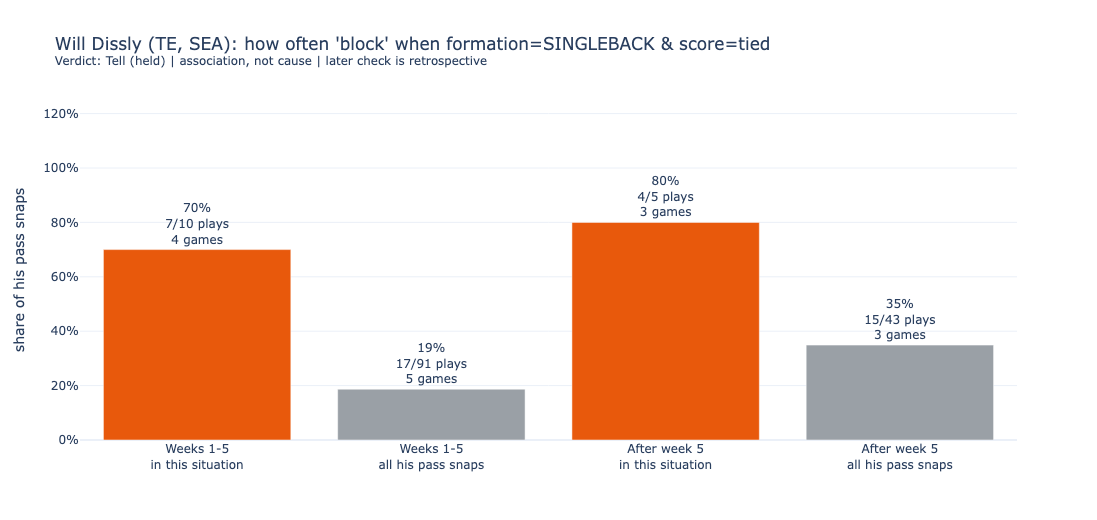

In [16]:
demo_rule = None
if team_eval.empty:
    print("Nothing to demo for this selection.")
elif CONFIG["DEMO_RULE_RANK"] >= len(team_eval):
    print("DEMO_RULE_RANK is beyond the {} tendencies found.".format(len(team_eval)))
else:
    demo_rule = team_eval.iloc[CONFIG["DEMO_RULE_RANK"]]
    fig = fig_tendency(demo_rule, CONFIG)
    save_fig(fig, "tendency.html", CONFIG)
    fig.show()

### Historical evidence (before the cutoff)
Every pre-cutoff play behind the tendency: supporting plays, exceptions and ambiguous labels.

In [17]:
if demo_rule is not None:
    before = rule_plays(pp, demo_rule, CONFIG, "before")
    display(before["evidence"].value_counts().rename("plays").to_frame())
    display(before)

,plays
evidence,
support,7
exception,3


,gameId,playId,nflId,week,opponent,quarter,gameClock,down,yardsToGo,formation,personnel,alignment,box,assignment,assignment_detail,evidence
0,2021091912,255,46189,2,TEN,1,11:23,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-R,heavy 7+,block,Pass Block / blockType=PA,support
1,2021091912,943,46189,2,TEN,2,14:46,1st,10,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-R,heavy 7+,block,Pass Block / blockType=PP,support
2,2021091912,4530,46189,2,TEN,5,08:19,1st,10,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-R,heavy 7+,block,Pass Block / blockType=PA,support
3,2021092612,54,46189,3,MIN,1,15:00,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-iR,heavy 7+,route,Pass Route / blockType=none,exception
4,2021100310,2086,46189,4,SF,3,12:14,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-R,heavy 7+,route,Pass Route / blockType=none,exception
5,2021100310,2328,46189,4,SF,3,08:53,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-R,heavy 7+,block,Pass Block / blockType=CL,support
6,2021100700,227,46189,5,LA,1,12:16,1st,10,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-R,6,block,Pass Block / blockType=CL,support
7,2021100700,523,46189,5,LA,1,06:31,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-R,heavy 7+,route,Pass Route / blockType=none,exception
8,2021100700,920,46189,5,LA,2,14:47,1st,10,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-R,6,block,Pass Block / blockType=PA,support
9,2021100700,1143,46189,5,LA,2,10:07,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-R,6,block,Pass Block / blockType=CL,support


### Freeze a later play at the snap
Same player, same situation, in a game after the cutoff. Only snap-time information is on screen. What does he do?

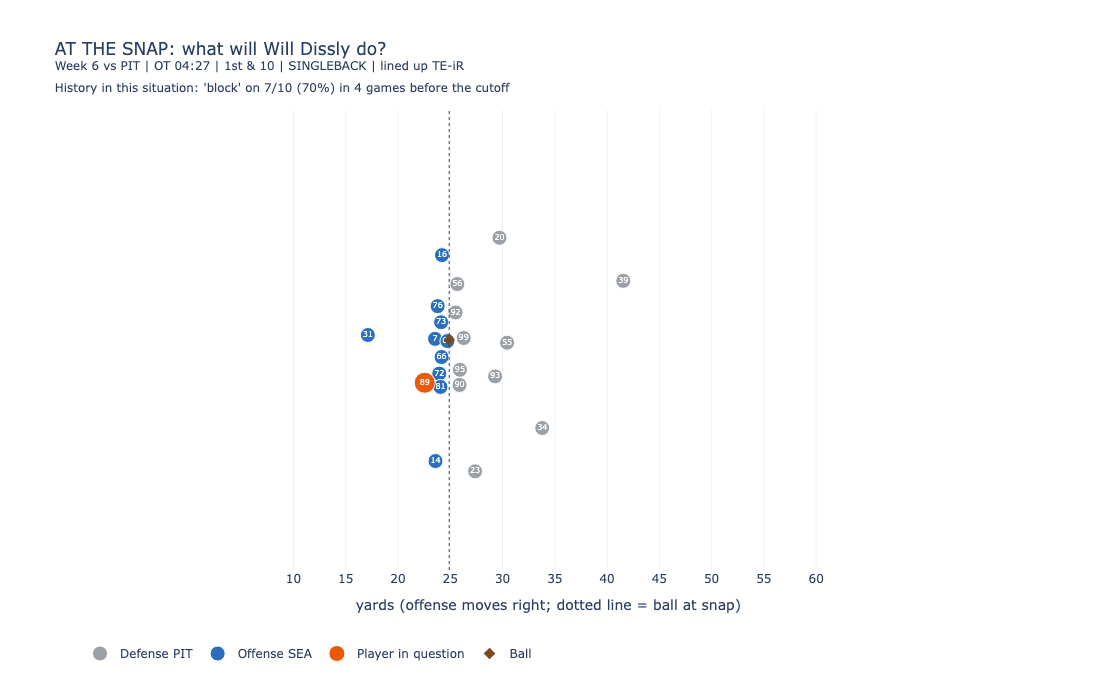

In [18]:
later_plays, confirm, exception = None, None, None
if demo_rule is not None:
    later_plays = rule_plays(pp, demo_rule, CONFIG, "later")
    sup = later_plays[later_plays["evidence"] == "support"]
    exc = later_plays[later_plays["evidence"] == "exception"]
    confirm = sup.iloc[0] if len(sup) else None
    exception = exc.iloc[0] if len(exc) else None
    if later_plays.empty:
        print("This situation did not occur for this player after the cutoff, so there is no later play to freeze.")


def show_play(row, label, reveal):
    """Draw one later play for the demo rule; label goes into the saved file name."""
    period = "OT" if row["quarter"] >= 5 else "Q{}".format(row["quarter"])
    snap_info = "Week {} vs {} | {} {} | {} & {} | {} | lined up {}".format(
        row["week"], row["opponent"], period, row["gameClock"], row["down"], row["yardsToGo"],
        row["formation"], row["alignment"])
    if reveal:
        title = "REVEAL: {} -> {} ({})<br><sup>{}</sup><br><sup>gameId {} playId {} nflId {}</sup>".format(
            demo_rule["displayName"], row["assignment"], row["evidence"], snap_info,
            row["gameId"], row["playId"], row["nflId"])
    else:
        title = "AT THE SNAP: what will {} do?<br><sup>{}</sup><br><sup>History in this situation: '{}' on {} before the cutoff</sup>".format(
            demo_rule["displayName"], snap_info, demo_rule["outcome"],
            _frac(demo_rule["disc_k"], demo_rule["disc_n"], demo_rule["disc_games"]))
    fig = fig_play(pp, tables, CONFIG, int(row["gameId"]), int(row["playId"]), int(row["nflId"]), title, reveal=reveal)
    if fig is not None:
        save_fig(fig, "{}_{}.html".format(label, "reveal" if reveal else "freeze"), CONFIG)
        fig.show()


if confirm is not None:
    show_play(confirm, "later_play", reveal=False)
elif later_plays is not None and len(later_plays):
    print("No later play in this situation followed the tendency. See the exception below.")

### Reveal

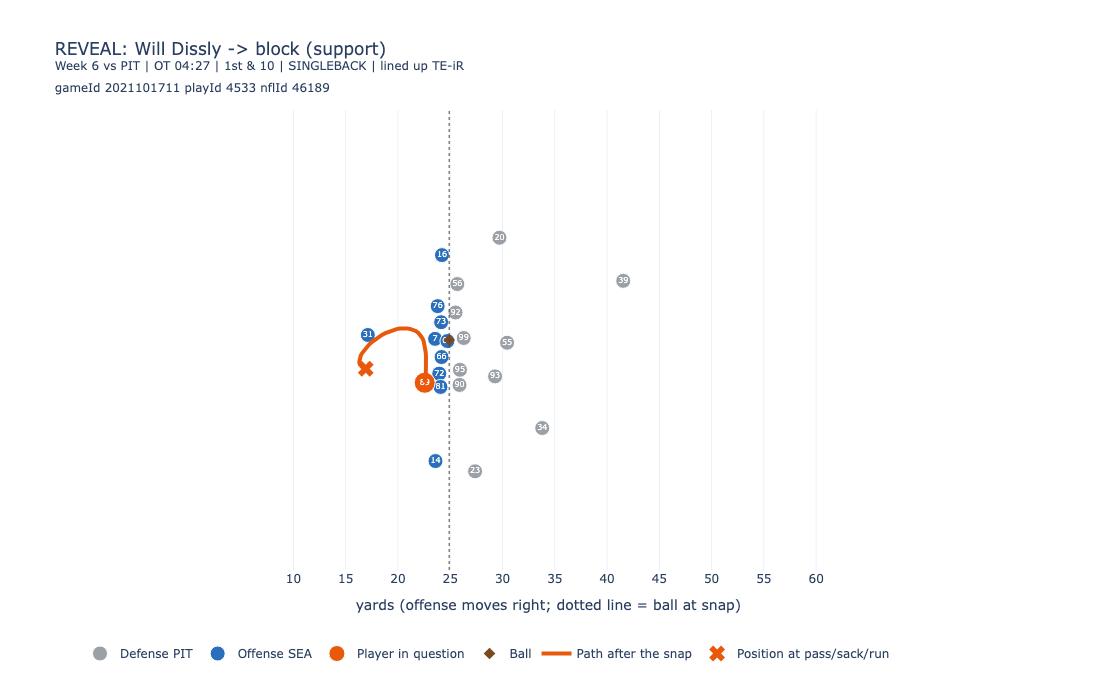

In [19]:
if confirm is not None:
    show_play(confirm, "later_play", reveal=True)

### An exception
A later play in the same situation where the player did something else. A tendency is not a guarantee.

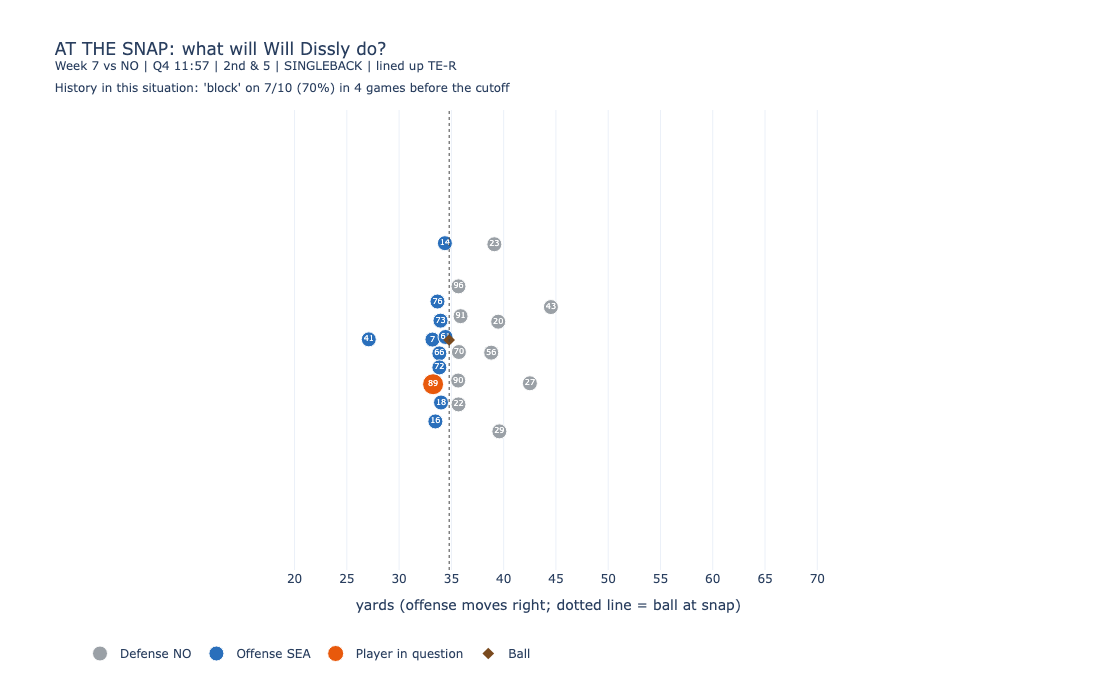

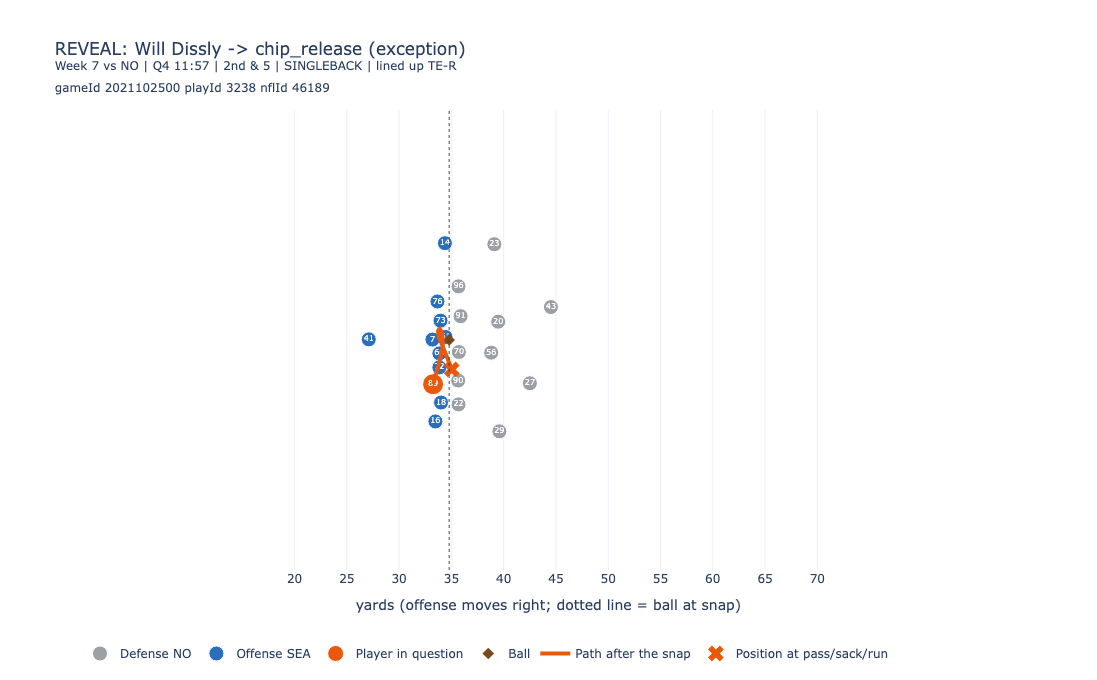

In [20]:
if exception is not None:
    show_play(exception, "exception", reveal=False)
    show_play(exception, "exception", reveal=True)
elif later_plays is not None and len(later_plays):
    print("No clean exception after the cutoff for this tendency ({} later plays).".format(len(later_plays)))

### Complete later-game results for this tendency
Every later play in the situation, not just the two shown above.

In [21]:
if later_plays is not None and len(later_plays):
    display(later_plays["evidence"].value_counts().rename("plays").to_frame())
    display(later_plays)
    later_plays.to_csv(Path(CONFIG["OUTPUT_DIR"]) / "later_plays_demo_rule.csv", index=False)

,plays
evidence,
support,4
exception,1


,gameId,playId,nflId,week,opponent,quarter,gameClock,down,yardsToGo,formation,personnel,alignment,box,assignment,assignment_detail,evidence
0,2021101711,4533,46189,6,PIT,5,04:27,1st,10,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-iR,heavy 7+,block,Pass Block / blockType=UP,support
1,2021102500,326,46189,7,NO,1,10:22,2nd,10,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-L,6,block,Pass Block / blockType=PA,support
2,2021102500,3238,46189,7,NO,4,11:57,2nd,5,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-R,heavy 7+,chip_release,Pass Route / blockType=SR,exception
3,2021102500,3305,46189,7,NO,4,10:38,2nd,6,SINGLEBACK,"1 RB, 2 TE, 2 WR",TE-R,heavy 7+,block,Pass Block / blockType=PA,support
4,2021103109,414,46189,8,JAX,1,06:26,2nd,5,SINGLEBACK,"1 RB, 1 TE, 3 WR",TE-R,heavy 7+,block,Pass Block / blockType=UP,support


## 7. League-wide scoreboard: how often does a discovered tendency hold?
The same procedure for every team, using the same thresholds. This is the reality check: it counts Tells, Traps and tendencies with too few later plays, and lists teams where nothing was found.

Top-10 tendencies per team, discovered on weeks 1-5 and checked on later weeks (retrospective).


,tendencies
verdict,
Too few later plays,122
Trap (did not hold),115
Tell (held),83


Of 198 tendencies with at least 5 later plays, 83 held (42%) across 28 teams.
Teams with no tendency meeting the thresholds: none


verdict,Tell (held),Too few later plays,Trap (did not hold),tendencies
team,,,,
ARI,1,3,6,10
ATL,0,5,5,10
BAL,0,10,0,10
BUF,0,10,0,10
CAR,8,1,1,10
CHI,6,2,2,10
CIN,3,2,5,10
CLE,2,3,5,10
DAL,3,2,5,10


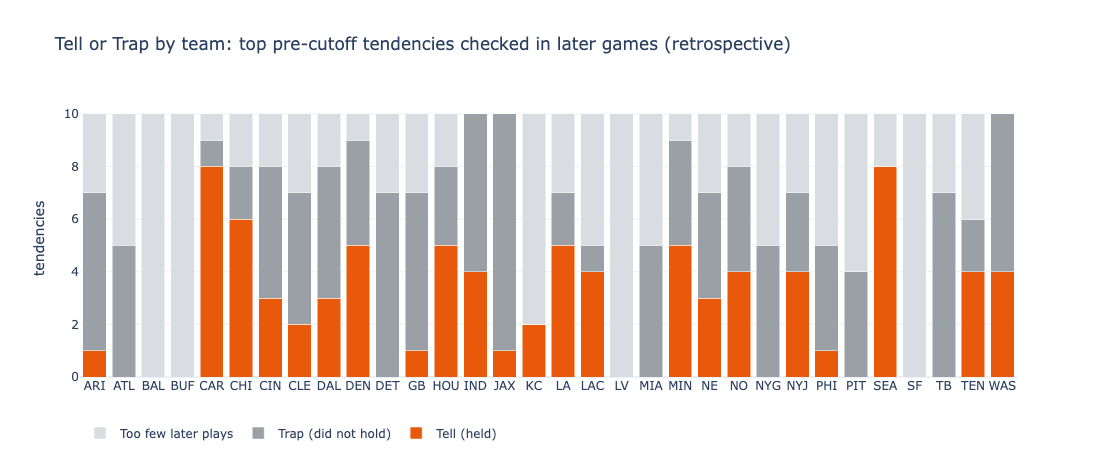

In [22]:
league_eval = evaluate(pp, top_rules(discover(pp, CONFIG), CONFIG), CONFIG)
all_teams = sorted(pp["team"].unique())
board = (league_eval.groupby(["team", "verdict"]).size().unstack(fill_value=0)
         .reindex(all_teams, fill_value=0))
board["tendencies"] = board.sum(axis=1)
print("Top-{} tendencies per team, discovered on weeks 1-{} and checked on later weeks (retrospective).".format(
    CONFIG["TOP_K"], CONFIG["CUTOFF_WEEK"]))
display(league_eval["verdict"].value_counts().rename("tendencies").to_frame())
checked = league_eval[league_eval["verdict"] != "Too few later plays"]
if len(checked):
    held = int((checked["verdict"] == "Tell (held)").sum())
    print("Of {} tendencies with at least {} later plays, {} held ({:.0%}) across {} teams.".format(
        len(checked), CONFIG["MIN_EVAL_PLAYS"], held, held / len(checked), checked["team"].nunique()))
print("Teams with no tendency meeting the thresholds:", [t for t in all_teams if board.loc[t, "tendencies"] == 0] or "none")
display(board)
Path(CONFIG["OUTPUT_DIR"]).mkdir(parents=True, exist_ok=True)
present(league_eval).to_csv(Path(CONFIG["OUTPUT_DIR"]) / "league_tendencies.csv", index=False)

fig = go.Figure()
for verdict, color in [("Tell (held)", COLORS["focus"]), ("Trap (did not hold)", COLORS["defense"]),
                       ("Too few later plays", "#d9dce1")]:
    if verdict in board.columns:
        fig.add_trace(go.Bar(x=board.index, y=board[verdict], name=verdict, marker_color=color))
fig.update_layout(barmode="stack", template="plotly_white", height=460, width=980,
                  title="Tell or Trap by team: top pre-cutoff tendencies checked in later games (retrospective)",
                  yaxis=dict(title="tendencies"), legend=dict(orientation="h", y=-0.15))
save_fig(fig, "league_scoreboard.html", CONFIG)
fig.show()